# Exploration des paramètres de génération CCSSP

Objectif : trouver des valeurs de `p_trans` et `p_acc` qui produisent des instances **ni triviales ni infaisables**.

| Métrique | Description | Cible |
|---|---|---|
| `feas_rate` | Fraction de scénarios où ∃ une séquence acceptée par les k automates (BFS exact sur l'automate produit) | > 50 % |
| `greedy_fail` | Fraction de scénarios où la séquence greedy est rejetée par ≥ 1 automate | > 90 % |
| `trivial_frac` | Fraction d'épisodes où le greedy satisfait déjà la contrainte de chance (P ≥ 1−ε) | < 10 % |

In [ ]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import product as iproduct

# --- chemin vers create_database_ssp_pesant.py (meme dossier que le notebook) ---
try:
    _nb_dir = Path(__vsc_ipynb_file__).parent  # VSCode
except NameError:
    _nb_dir = Path.cwd()  # Jupyter classique
if str(_nb_dir) not in sys.path:
    sys.path.insert(0, str(_nb_dir))

from create_database_ssp_pesant import (
    generate_scenario, generate_base_automaton, perturb_automaton
)


# ─── helpers ──────────────────────────────────────────────────────────────

def greedy_sequence(profit):
    return np.argmax(profit, axis=1)


def single_aut_accepts(aut, seq):
    q = 0
    for a in seq:
        q = int(aut['delta'][q, a])
        if q < 0:
            return False
    return bool(aut['accepting'][q])


def all_accept(automata, seq):
    return all(single_aut_accepts(aut, seq) for aut in automata)


def product_bfs_feasible(automata, n, m):
    # BFS exact sur l'automate produit (au plus Q^k etats)
    k = len(automata)
    reach = {tuple([0] * k)}
    for _ in range(n):
        nxt = set()
        for states in reach:
            for a in range(m):
                ns, dead = [], False
                for j, q in enumerate(states):
                    q2 = int(automata[j]['delta'][q, a])
                    if q2 < 0:
                        dead = True
                        break
                    ns.append(q2)
                if not dead:
                    nxt.add(tuple(ns))
        reach = nxt
        if not reach:
            return False
    return any(
        all(automata[j]['accepting'][s[j]] for j in range(k))
        for s in reach
    )


def batch_accept(automata, seqs):
    # seqs: (S, n) int array -> (S,) bool. Vectorise sur S sequences simultanement.
    S, n_len = seqs.shape
    accepted = np.ones(S, dtype=bool)
    for aut in automata:
        delta, acc = aut['delta'], aut['accepting']
        q = np.zeros(S, dtype=int)
        alive = np.ones(S, dtype=bool)
        for t in range(n_len):
            a = seqs[:, t]
            q_next = delta[q, a]  # fancy indexing (S,)
            alive = alive & (q_next >= 0)
            q = np.where(alive, q_next, 0)
        accepted = accepted & alive & acc[q]
    return accepted


try:
    from tqdm.auto import tqdm
    wrap = tqdm
except ImportError:
    wrap = lambda x, **kw: x

print('Imports OK.')

Imports OK.


In [ ]:
# ══════════════════════════════════════════════════════
# Paramètres — modifier ici
# ══════════════════════════════════════════════════════

n    = 50    # longueur de la sequence
m    = 5     # taille de l'alphabet |W|
k    = 2     # automates par scenario
Q    = 10     # etats par automate
eps  = 0.10  # niveau de risque (contrainte : P >= 1 - eps)
N    = 200   # scenarios par episode (plus grand = plus precis, plus lent)
n_ep = 10    # replications (episodes)
seed = 42

# Grille de parametres a explorer
p_trans_grid = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]
p_acc_grid   = [0.1, 0.2, 0.3, 0.5, 0.7]

n_rand_seq = 300  # sequences aleatoires echantillonnees pour estimer best_rand

print(f'Grille : {len(p_trans_grid)} x {len(p_acc_grid)} = {len(p_trans_grid)*len(p_acc_grid)} combinaisons')
print(f'Automate produit : au plus Q^k = {Q**k} etats')
print(f'Par combinaison  : {n_ep} episodes x {N} scenarios')

Grille : 6 x 5 = 30 combinaisons
Automate produit : au plus Q^k = 100 etats
Par combinaison  : 10 episodes x 200 scenarios


## 1 · Test rapide sur un seul point

Avant de lancer la grille complète, vérifier le comportement sur un seul `(p_trans, p_acc)`.

In [ ]:
pt_test, pa_test = 0.7, 0.3
n_quick = 500

rng_t = np.random.default_rng(seed)
profit_t = rng_t.integers(0, 101, size=(n, m))
greedy_t = greedy_sequence(profit_t)

n_feas_t = n_fail_t = 0
for _ in range(n_quick):
    aut_t = generate_scenario(k, Q, m, n, pt_test, pa_test, rng_t)
    if product_bfs_feasible(aut_t, n, m):
        n_feas_t += 1
    if not all_accept(aut_t, greedy_t):
        n_fail_t += 1

print(f'p_trans={pt_test}, p_acc={pa_test}, n={n}, k={k}, Q={Q}')
print(f'  feas_rate   : {n_feas_t / n_quick:.3f}  (fraction de scenarios faisables)')
print(f'  greedy_fail : {n_fail_t / n_quick:.3f}  (fraction ou greedy est rejete)')

p_trans=0.7, p_acc=0.3, n=50, k=2, Q=10
  feas_rate   : 0.936  (fraction de scenarios faisables)
  greedy_fail : 1.000  (fraction ou greedy est rejete)


## 2 · Sweep sur la grille (p_trans, p_acc)

In [ ]:
def analyze_params(p_trans, p_acc, n, m, k, Q, N, n_ep, eps,
                   n_rand_seq=300, seed_base=42):
    rng = np.random.default_rng(seed_base)
    feas_rates, greedy_fail_rates, best_rand_rates = [], [], []
    trivial = 0

    for ep in range(n_ep):
        profit = rng.integers(0, 101, size=(n, m))
        greedy_seq = greedy_sequence(profit)
        rand_seqs = rng.integers(0, m, size=(n_rand_seq, n))

        n_feas = n_greedy_fail = 0
        rand_pass_counts = np.zeros(n_rand_seq, dtype=int)

        for _ in range(N):
            automata = generate_scenario(k, Q, m, n, p_trans, p_acc, rng)
            if product_bfs_feasible(automata, n, m):
                n_feas += 1
            if not all_accept(automata, greedy_seq):
                n_greedy_fail += 1
            rand_pass_counts += batch_accept(automata, rand_seqs).astype(int)

        feas_rates.append(n_feas / N)
        greedy_fail_rates.append(n_greedy_fail / N)
        best_rand_rates.append(rand_pass_counts.max() / N)

        # Episode trivial : greedy passe la contrainte de chance
        if (1.0 - n_greedy_fail / N) >= (1.0 - eps):
            trivial += 1

    return {
        'feas_rate':    float(np.mean(feas_rates)),
        'greedy_fail':  float(np.mean(greedy_fail_rates)),
        'best_rand':    float(np.mean(best_rand_rates)),
        'trivial_frac': trivial / n_ep,
    }

In [41]:
combos = list(iproduct(p_trans_grid, p_acc_grid))
results = {}

for pt, pa in wrap(combos, desc='sweep Pesant'):
    results[(pt, pa)] = analyze_params(
        pt, pa, n, m, k, Q, N, n_ep, eps,
        n_rand_seq=n_rand_seq, seed_base=seed
    )

print('Termine.')

sweep Pesant:   0%|          | 0/30 [00:00<?, ?it/s]

KeyboardInterrupt: 

## 3 · Heatmaps

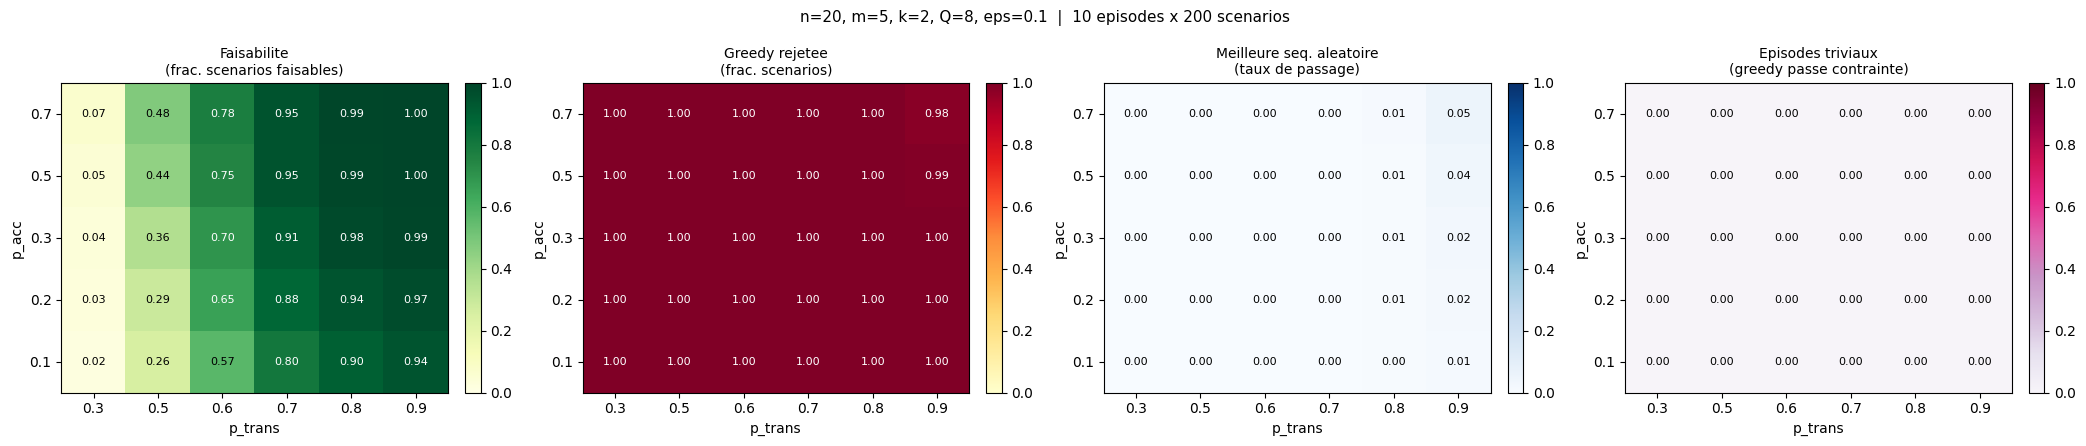

In [ ]:
def to_matrix(key):
    mat = np.zeros((len(p_acc_grid), len(p_trans_grid)))
    for i, pa in enumerate(p_acc_grid):
        for j, pt in enumerate(p_trans_grid):
            mat[i, j] = results[(pt, pa)][key]
    return mat


metrics_cfg = [
    ('feas_rate',   'Faisabilite\n(frac. scenarios faisables)',       'YlGn'),
    ('greedy_fail', 'Greedy rejetee\n(frac. scenarios)',              'YlOrRd'),
    ('best_rand',   'Meilleure seq. aleatoire\n(taux de passage)',    'Blues'),
    ('trivial_frac','Episodes triviaux\n(greedy passe contrainte)',   'PuRd'),
]

fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))

for ax, (key, title, cmap) in zip(axes, metrics_cfg):
    mat = to_matrix(key)
    im = ax.imshow(mat, cmap=cmap, vmin=0, vmax=1, aspect='auto', origin='lower')
    ax.set_xticks(range(len(p_trans_grid)))
    ax.set_xticklabels(p_trans_grid)
    ax.set_yticks(range(len(p_acc_grid)))
    ax.set_yticklabels(p_acc_grid)
    ax.set_xlabel('p_trans')
    ax.set_ylabel('p_acc')
    ax.set_title(title, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for i in range(len(p_acc_grid)):
        for j in range(len(p_trans_grid)):
            v = mat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    fontsize=8, color='white' if v > 0.65 else 'black')

plt.suptitle(f'n={n}, m={m}, k={k}, Q={Q}, eps={eps}  |  {n_ep} episodes x {N} scenarios',
             fontsize=11)
plt.tight_layout()
plt.savefig('param_sweep_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()

## 4 · Table récapitulative — zone cible

In [ ]:
# Seuils definissant la zone cible
seuil_feas    = 0.50   # au moins 50 % des scenarios ont une solution
seuil_trivial = 0.10   # moins de 10 % des episodes sont triviaux

print(f'Seuils : feas_rate >= {seuil_feas:.0%}  |  trivial_frac <= {seuil_trivial:.0%}')
print()
header = f'{"p_trans":>8} {"p_acc":>6} {"feas":>6} {"greedy_fail":>12} {"best_rand":>10} {"trivial":>8}  cible?'
print(header)
print('-' * len(header))
for pt in p_trans_grid:
    for pa in p_acc_grid:
        r = results[(pt, pa)]
        ok = r['feas_rate'] >= seuil_feas and r['trivial_frac'] <= seuil_trivial
        marker = 'V' if ok else ''
        print(
            f'{pt:>8.2f} {pa:>6.2f} {r["feas_rate"]:>6.3f}'
            f' {r["greedy_fail"]:>12.3f} {r["best_rand"]:>10.3f}'
            f' {r["trivial_frac"]:>8.3f}  {marker}'
        )

Seuils : feas_rate >= 50%  |  trivial_frac <= 10%

 p_trans  p_acc   feas  greedy_fail  best_rand  trivial  cible?
---------------------------------------------------------------
    0.30   0.10  0.016        1.000      0.000    0.000  
    0.30   0.20  0.029        1.000      0.000    0.000  
    0.30   0.30  0.035        1.000      0.000    0.000  
    0.30   0.50  0.049        1.000      0.000    0.000  
    0.30   0.70  0.069        1.000      0.000    0.000  
    0.50   0.10  0.257        1.000      0.000    0.000  
    0.50   0.20  0.292        1.000      0.000    0.000  
    0.50   0.30  0.360        1.000      0.000    0.000  
    0.50   0.50  0.439        1.000      0.000    0.000  
    0.50   0.70  0.480        1.000      0.000    0.000  
    0.60   0.10  0.570        1.000      0.000    0.000  V
    0.60   0.20  0.653        1.000      0.000    0.000  V
    0.60   0.30  0.699        1.000      0.000    0.000  V
    0.60   0.50  0.749        1.000      0.000    0.000  V
    0

## 5 · Effet de la longueur de séquence n

Pour un point `(p_trans, p_acc)` fixe, montrer comment les métriques évoluent avec `n`.
Utile pour choisir `n` : trop petit → risque de trivialité, trop grand → risque d'infaisabilité.

p_trans=0.7, p_acc=0.3, k=2, Q=8, eps=0.1
   n   feas  greedy_fail  best_rand  trivial
----------------------------------------------
   5  0.823        0.999      0.017    0.000
   8  0.883        1.000      0.007    0.000
  10  0.908        0.999      0.007    0.000
  15  0.907        1.000      0.004    0.000
  20  0.908        1.000      0.001    0.000
  30  0.920        1.000      0.000    0.000


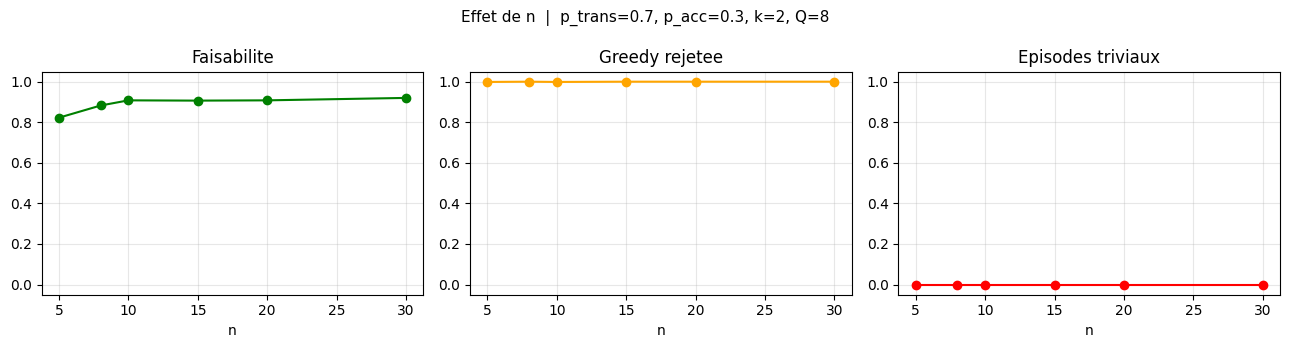

In [ ]:
pt_n, pa_n = 0.7, 0.3   # point a analyser
n_values   = [5, 8, 10, 15, 20, 30]

print(f'p_trans={pt_n}, p_acc={pa_n}, k={k}, Q={Q}, eps={eps}')
print(f'{"n":>4} {"feas":>6} {"greedy_fail":>12} {"best_rand":>10} {"trivial":>8}')
print('-' * 46)

n_sweep = {}
for n_val in n_values:
    r = analyze_params(pt_n, pa_n, n_val, m, k, Q,
                       N=150, n_ep=5, eps=eps,
                       n_rand_seq=100, seed_base=seed)
    n_sweep[n_val] = r
    flag = '  <- trivial!' if r['trivial_frac'] > 0.1 else ''
    flag = flag or ('  <- infaisable!' if r['feas_rate'] < 0.1 else '')
    print(
        f'{n_val:>4} {r["feas_rate"]:>6.3f}'
        f' {r["greedy_fail"]:>12.3f} {r["best_rand"]:>10.3f}'
        f' {r["trivial_frac"]:>8.3f}{flag}'
    )

# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
ns = list(n_sweep.keys())
for ax, key, title, color in zip(
    axes,
    ['feas_rate', 'greedy_fail', 'trivial_frac'],
    ['Faisabilite', 'Greedy rejetee', 'Episodes triviaux'],
    ['green', 'orange', 'red']
):
    ax.plot(ns, [n_sweep[nv][key] for nv in ns], 'o-', color=color)
    ax.set_xlabel('n')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Effet de n  |  p_trans={pt_n}, p_acc={pa_n}, k={k}, Q={Q}', fontsize=11)
plt.tight_layout()
plt.show()

## Interprétation

**Effets des paramètres :**
- `p_trans` bas → beaucoup de transitions mortes → peu de chemins survivent → `feas_rate` chute
- `p_acc` bas → peu d'états acceptants → même les chemins qui survivent n'aboutissent pas → `feas_rate` chute
- `n` petit → le greedy peut traverser toutes les transitions sans mourir → risque de trivialité
- `n` grand → quasi-aucun chemin fixé ne survit → `greedy_fail` ≈ 1 partout (peu discriminant)

**Zone cible :**
- `feas_rate > 50 %` : il existe des séquences faisables dans la majorité des scénarios
- `trivial_frac < 10 %` : le greedy ne satisfait pas trivialement la contrainte de chance
- `best_rand` modéré (0.1–0.5) : la contrainte est non triviale mais des solutions existent

**Note sur `greedy_fail` :** pour n ≥ 10 et p_trans ≤ 0.9, cette métrique est quasi-systématiquement > 99 % (car p_trans^n → 0). Elle ne discrimine pas les paramètres pour des séquences longues — c'est `feas_rate` et `best_rand` qui comptent.

---
## 6 · Mode base corrélé — sweep sur p_keep

Idée : chaque épisode génère k **automates de base** entièrement définis (toutes transitions actives, états acceptants Bernoulli(p_acc)). Chaque scénario est une **perturbation** de ces bases : chaque transition est conservée avec probabilité `p_keep`, sinon supprimée.

Les scénarios d'un même épisode partagent la même structure de base → la contrainte de chance peut être satisfaite même pour `n` grand.

**`p_keep` contrôle la difficulté** : 1.0 = tous les scénarios identiques (trivial), 0.0 = toutes transitions mortes (infaisable).

### Métrique principale : faisabilité chance-contrainte (CC)

La faisabilité **par scénario** (BFS indépendant) n'est pas la bonne métrique : un scénario peut admettre une séquence valide qui n'est valide pour aucun autre. Ce qui compte, c'est :

> **Pour chaque épisode, quelle est la plus grande fraction de scénarios pouvant accepter *simultanément* la même séquence ?**

Pour une séquence x et un épisode donné, on note f(x) = #{i : scénario i accepte x} / N. La métrique d'intérêt est max_x f(x). Si max_x f(x) ≥ 1 − ε, l'instance est globalement faisable (contrainte de chance satisfaite).

`cc_feas_rate` = fraction d'épisodes où max_x f(x) ≥ 1 − ε (estimé par `n_rand_seq` séquences aléatoires — **borne inférieure**).  
`best_rand` = E[max_x f(x)] sur les épisodes.

In [47]:
# ══════════════════════════════════════════════════════
# Paramètres du sweep base mode — modifier ici
# ══════════════════════════════════════════════════════

#p_keep_grid  = [0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
p_keep_grid  = [0.9,0.91,0.92,0.93,0.94,0.95,0.96,0.97,0.98,0.99,1.0]
p_acc_values = [0.3, 0.5, 0.7, 0.9]   # tester plusieurs p_acc

# n, m, k, Q, N, n_ep, eps, seed, n_rand_seq herites de la section precedente
print(f'n={n}, m={m}, k={k}, Q={Q}, eps={eps}')
print(f'p_keep_grid  = {p_keep_grid}')
print(f'p_acc_values = {p_acc_values}')
print(f'{len(p_keep_grid)} x {len(p_acc_values)} = {len(p_keep_grid)*len(p_acc_values)} combinaisons')

n=50, m=5, k=2, Q=10, eps=0.1
p_keep_grid  = [0.9, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99, 1.0]
p_acc_values = [0.3, 0.5, 0.7, 0.9]
11 x 4 = 44 combinaisons


In [48]:
def analyze_params_base(p_acc, p_keep, n, m, k, Q, N, n_ep, eps,
                        n_rand_seq=300, seed_base=42):
    """
    Pour chaque épisode, estime max_x f(x) via n_rand_seq séquences aléatoires,
    où f(x) = fraction de scénarios acceptant x simultanément.
    Retourne cc_feas_rate = fraction d'épisodes où max f(x) >= 1 - eps.
    """
    rng = np.random.default_rng(seed_base)
    cc_feas_count = 0          # épisodes où max f(x) >= 1 - eps
    best_rand_rates = []       # max f(x) par épisode
    greedy_fail_rates = []
    trivial = 0

    for ep in range(n_ep):
        profit = rng.integers(0, 101, size=(n, m))
        greedy_seq = greedy_sequence(profit)
        rand_seqs = rng.integers(0, m, size=(n_rand_seq, n))

        base_automata = [generate_base_automaton(Q, m, p_acc, rng) for _ in range(k)]

        n_greedy_fail = 0
        rand_pass_counts = np.zeros(n_rand_seq, dtype=int)

        for _ in range(N):
            automata = [perturb_automaton(base, p_keep, rng) for base in base_automata]
            if not all_accept(automata, greedy_seq):
                n_greedy_fail += 1
            rand_pass_counts += batch_accept(automata, rand_seqs).astype(int)

        best_frac = rand_pass_counts.max() / N
        best_rand_rates.append(best_frac)
        greedy_fail_rates.append(n_greedy_fail / N)

        if best_frac >= 1.0 - eps:
            cc_feas_count += 1

        # Trivial : la séquence greedy satisfait déjà la contrainte de chance
        if (1.0 - n_greedy_fail / N) >= (1.0 - eps):
            trivial += 1

    return {
        'cc_feas_rate': cc_feas_count / n_ep,        # borne inf. sur la faisabilité CC
        'best_rand':    float(np.mean(best_rand_rates)),
        'greedy_fail':  float(np.mean(greedy_fail_rates)),
        'trivial_frac': trivial / n_ep,
    }

In [49]:
results_base = {}

for pa in wrap(p_acc_values, desc='p_acc'):
    for pk in p_keep_grid:
        results_base[(pa, pk)] = analyze_params_base(
            pa, pk, n, m, k, Q, N, n_ep, eps,
            n_rand_seq=n_rand_seq, seed_base=seed
        )

print('Termine.')

p_acc:   0%|          | 0/4 [00:00<?, ?it/s]

Termine.


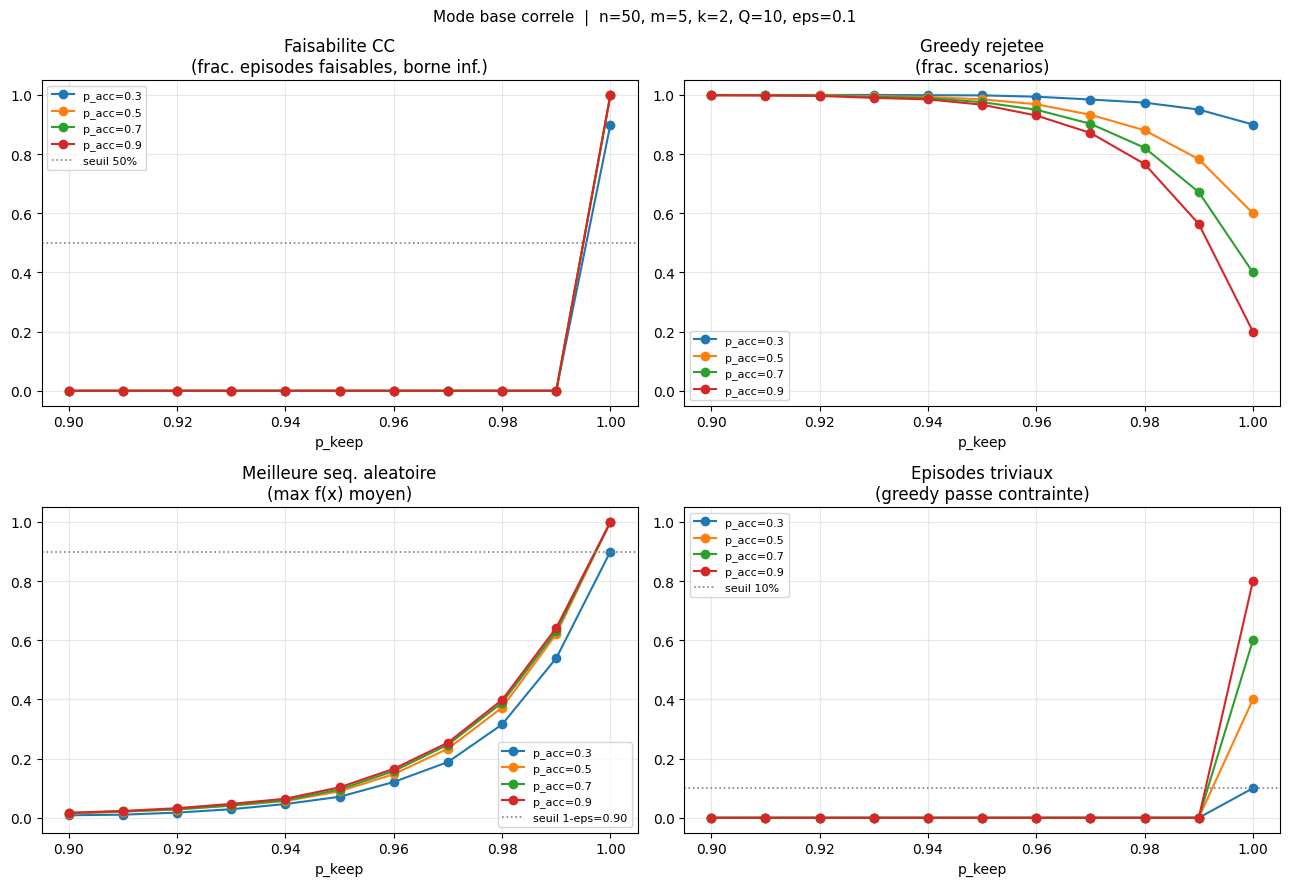

In [50]:
metrics_base = [
    ('cc_feas_rate', 'Faisabilite CC\n(frac. episodes faisables, borne inf.)', 'green'),
    ('greedy_fail',  'Greedy rejetee\n(frac. scenarios)',                       'orange'),
    ('best_rand',    'Meilleure seq. aleatoire\n(max f(x) moyen)',               'steelblue'),
    ('trivial_frac', 'Episodes triviaux\n(greedy passe contrainte)',             'red'),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (key, title, color) in zip(axes.flat, metrics_base):
    for pa in p_acc_values:
        vals = [results_base[(pa, pk)][key] for pk in p_keep_grid]
        ax.plot(p_keep_grid, vals, 'o-', label=f'p_acc={pa}')
    if 'cc_feas' in key:
        ax.axhline(0.5, color='gray', ls=':', lw=1.2, label='seuil 50%')
    if 'trivial' in key:
        ax.axhline(0.1, color='gray', ls=':', lw=1.2, label='seuil 10%')
    if 'best_rand' in key:
        ax.axhline(1.0 - eps, color='gray', ls=':', lw=1.2, label=f'seuil 1-eps={1-eps:.2f}')
    ax.set_xlabel('p_keep')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Mode base correle  |  n={n}, m={m}, k={k}, Q={Q}, eps={eps}', fontsize=11)
plt.tight_layout()
plt.savefig('base_mode_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

In [51]:
seuil_cc_feas  = 0.50   # au moins 50 % des episodes ont max f(x) >= 1-eps
seuil_trivial  = 0.10   # moins de 10 % des episodes sont triviaux

print(f'Mode base correle | n={n}, m={m}, k={k}, Q={Q}, eps={eps}')
print(f'Seuils : cc_feas_rate >= {seuil_cc_feas:.0%}  |  trivial_frac <= {seuil_trivial:.0%}')
print(f'(cc_feas_rate = fraction episodes ou max_x f(x) >= {1-eps:.2f}, borne inf. via {n_rand_seq} seq. aleat.)')
print()
hdr = f'{"p_acc":>6} {"p_keep":>7} {"cc_feas":>8} {"greedy_fail":>12} {"best_rand":>10} {"trivial":>8}  cible?'
print(hdr)
print('-' * len(hdr))
for pa in p_acc_values:
    for pk in p_keep_grid:
        r = results_base[(pa, pk)]
        ok = r['cc_feas_rate'] >= seuil_cc_feas and r['trivial_frac'] <= seuil_trivial
        marker = 'V' if ok else ''
        print(
            f'{pa:>6.2f} {pk:>7.2f} {r["cc_feas_rate"]:>8.3f}'
            f' {r["greedy_fail"]:>12.3f} {r["best_rand"]:>10.3f}'
            f' {r["trivial_frac"]:>8.3f}  {marker}'
        )

Mode base correle | n=50, m=5, k=2, Q=10, eps=0.1
Seuils : cc_feas_rate >= 50%  |  trivial_frac <= 10%
(cc_feas_rate = fraction episodes ou max_x f(x) >= 0.90, borne inf. via 300 seq. aleat.)

 p_acc  p_keep  cc_feas  greedy_fail  best_rand  trivial  cible?
----------------------------------------------------------------
  0.30    0.90    0.000        1.000      0.009    0.000  
  0.30    0.91    0.000        1.000      0.010    0.000  
  0.30    0.92    0.000        1.000      0.018    0.000  
  0.30    0.93    0.000        1.000      0.029    0.000  
  0.30    0.94    0.000        0.999      0.046    0.000  
  0.30    0.95    0.000        0.998      0.071    0.000  
  0.30    0.96    0.000        0.994      0.121    0.000  
  0.30    0.97    0.000        0.985      0.189    0.000  
  0.30    0.98    0.000        0.974      0.316    0.000  
  0.30    0.99    0.000        0.951      0.539    0.000  
  0.30    1.00    0.900        0.900      0.900    0.100  V
  0.50    0.90    0.000    